Nhiệm vụ: Xây dựng một mô hình Deep Learning có khả năng dự đoán xác suất giá đóng cửa của cổ phiếu SPY vào ngày mai sẽ cao hơn hay thấp hơn giá đóng cửa hôm nay, dựa trên chuỗi giá đóng cửa của 60 ngày gần nhất.

Hình ảnh liên tưởng: Hãy tưởng tượng bạn là một nhà phân tích kỹ thuật (technical analyst). Thay vì nhìn vào biểu đồ và vẽ các đường trendline bằng tay, bạn xây dựng một "bộ não" nhân tạo có khả năng "nhớ" và nhận ra các mẫu hình (patterns) trong biến động giá của 60 ngày qua. Dựa trên "trí nhớ" về các mẫu hình này, nó sẽ đưa ra dự báo về khả năng giá sẽ đi lên hay đi xuống trong phiên tiếp theo. LSTM chính là một dạng "trí nhớ" phức tạp cho mạng nơ-ron.

Bước 1: Thu thập "Dữ liệu Quá khứ" - Tải và Chuẩn bị Dữ liệu Giá SPY
Chúng ta sẽ sử dụng thư viện yfinance để tải dữ liệu giá lịch sử của quỹ ETF SPY.

/tmp/ipython-input-2541345705.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start='2020-01-01', end='2025-12-31')
[*********************100%***********************]  1 of 1 completed


Fetched 2181 data points for BTC-USD.


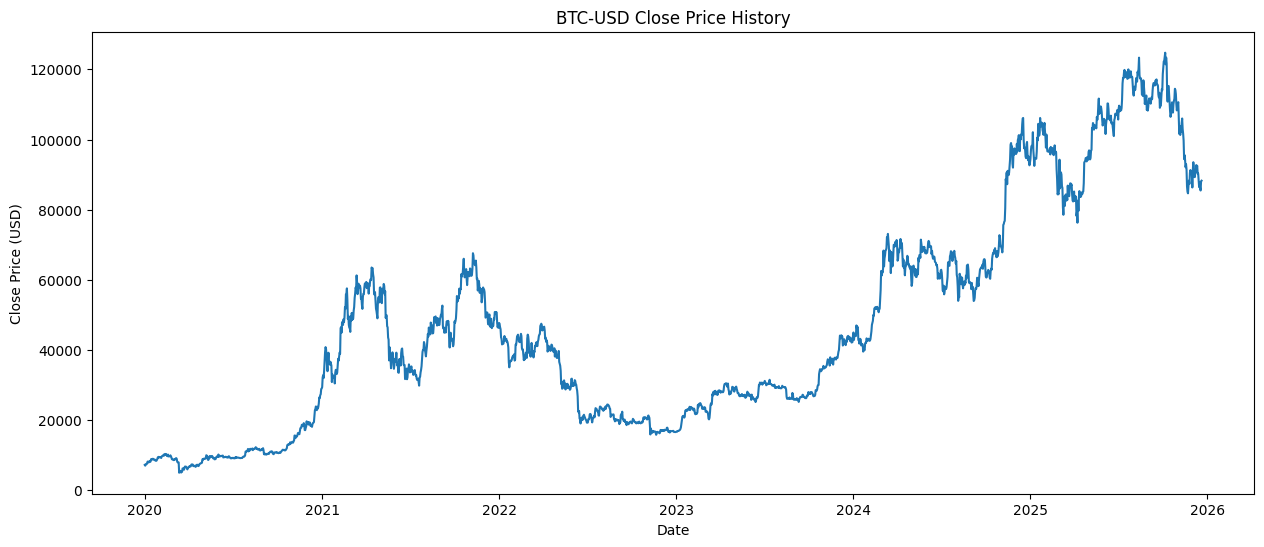

In [1]:
# Step 1: Import libraries and fetch stock data
import yfinance as yf
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

# Fetch historical data for SPY from Yahoo Finance
ticker = 'BTC-USD'
data = yf.download(ticker, start='2020-01-01', end='2025-12-31')

# We only need the 'Close' price for this exercise
close_prices = data['Close'].values.reshape(-1, 1)

# Display the data
print(f"Fetched {len(close_prices)} data points for {ticker}.")
plt.figure(figsize=(15, 6))
plt.plot(data.index, close_prices)
plt.title(f"{ticker} Close Price History")
plt.xlabel("Date")
plt.ylabel("Close Price (USD)")
plt.show()

Giải thích:
- yfinance là một công cụ mạnh mẽ để lấy dữ liệu tài chính miễn phí.
- Chúng ta chỉ lấy cột giá đóng cửa (Close) và chuyển nó thành một mảng NumPy.

Bước 2: Chuẩn bị "Nguyên liệu" - Chuẩn hóa và Tạo Dữ liệu Huấn luyện

Đây là bước quan trọng và khác biệt nhất khi làm việc với chuỗi thời gian.

- Chuẩn hóa (Scaling): Tương tự các bài trước, chúng ta cần đưa dữ liệu về một khoảng nhỏ (thường là [0, 1]) để mô hình học tốt hơn.
- Tạo các cặp Input-Output: Chúng ta cần biến chuỗi giá liên tục thành các mẫu (samples) mà mô hình có thể học. Với mỗi ngày t, chúng ta sẽ tạo một cặp:
  - Input (X): Chuỗi giá của 60 ngày trước đó (từ t-60 đến t-1).
  - Output (y): Một nhãn 1 nếu giá ngày t > giá ngày t-1 (tăng), và 0 nếu ngược lại (giảm hoặc không đổi).

In [2]:
# Step 2: Normalize and create training sequences

# Normalize the data to be between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(close_prices)

# Create sequences of data
look_back_period = 60
X = []
y = []

for i in range(look_back_period, len(scaled_prices)):
    # Input: The sequence of the last 'look_back_period' days
    X.append(scaled_prices[i-look_back_period:i, 0])

    # Output: 1 if the price goes up tomorrow, 0 otherwise
    if scaled_prices[i, 0] > scaled_prices[i-1, 0]:
        y.append(1)
    else:
        y.append(0)

# Convert to numpy arrays
X, y = np.array(X), np.array(y)

# Reshape X to be [samples, timesteps, features] which is the format required by LSTM
# In our case, 'features' is 1 because we only use the Close price.
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

print(f"Shape of X: {X.shape}") # (Number of samples, 60 timesteps, 1 feature)
print(f"Shape of y: {y.shape}")

Shape of X: (2121, 60, 1)
Shape of y: (2121,)


Giải thích:
- MinMaxScaler là công cụ chuẩn hóa dữ liệu.
- Vòng lặp for trượt qua toàn bộ chuỗi giá để tạo ra các "cửa sổ" dữ liệu 60 ngày làm input (X) và nhãn "tăng/giảm" làm output (y).
- Bước np.reshape cuối cùng rất quan trọng, nó định dạng dữ liệu đầu vào theo đúng chuẩn 3 chiều mà lớp LSTM yêu cầu.

Bước 3: Xây dựng "Trí nhớ" - Kiến trúc Mạng LSTM

LSTM là một loại RNN đặc biệt, được thiết kế để "nhớ" các thông tin quan trọng trong một chuỗi dài và quên đi những thông tin không cần thiết. Điều này làm cho nó rất phù hợp với dữ liệu chuỗi thời gian.

In [3]:
# Step 3: Build the LSTM model

model = Sequential([
    # First LSTM layer with 50 units. 'return_sequences=True' is needed
    # because we are stacking another LSTM layer on top.
    LSTM(units=50, return_sequences=True, input_shape=(X.shape[1], 1)),
    Dropout(0.2), # Dropout layer to prevent overfitting

    # Second LSTM layer
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),

    # A dense hidden layer
    Dense(units=25, activation='relu'),

    # Output layer with 1 neuron and a sigmoid activation function
    # Sigmoid is perfect for binary classification as it outputs a probability between 0 and 1.
    Dense(units=1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Step 4: Compile and train the model

# Split data into training and testing sets (80% train, 20% test)
# It's crucial to split time series data chronologically
split_index = int(len(X) * 0.8)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

model.compile(optimizer='adam',
              loss='binary_crossentropy', # Loss function for binary classification
              metrics=['accuracy'])

print("\nStarting LSTM training...")
history = model.fit(X_train, y_train, epochs=25, batch_size=32, validation_data=(X_test, y_test))
print("Training finished!")


Starting LSTM training...
Epoch 1/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.5017 - loss: 0.6935 - val_accuracy: 0.5035 - val_loss: 0.6931
Epoch 2/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.4978 - loss: 0.6934 - val_accuracy: 0.5035 - val_loss: 0.6930
Epoch 3/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.4991 - loss: 0.6933 - val_accuracy: 0.5035 - val_loss: 0.6932
Epoch 4/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.5090 - loss: 0.6934 - val_accuracy: 0.5035 - val_loss: 0.6930
Epoch 5/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.5295 - loss: 0.6920 - val_accuracy: 0.4965 - val_loss: 0.6961
Epoch 6/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.4920 - loss: 0.6946 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 7/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5222 - loss: 0.6920 - val_accuracy: 0.4965 - val_loss: 0.6931
Epoch 8/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.5146 - loss: 0.692

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5255 - loss: 0.6929

Test Accuracy on unseen data: 50.59%


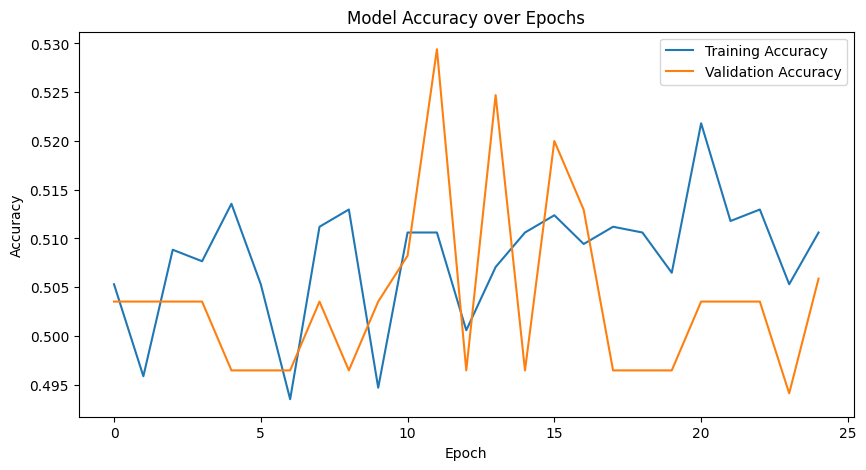

In [5]:
# Step 5: Evaluate the model

# Evaluate on the test set
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy on unseen data: {test_acc*100:.2f}%")

# Visualize training history
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Get predicted probabilities
predicted_probabilities = model.predict(X_test)

# Handle both (n,) and (n, 1) and (n, 2) cases robustly
if predicted_probabilities.ndim == 2:
    if predicted_probabilities.shape[1] == 1:
        # Binary classification with sigmoid output
        probs = predicted_probabilities.flatten()
    elif predicted_probabilities.shape[1] == 2:
        # Binary classification with softmax output → take class 1
        probs = predicted_probabilities[:, 1]
    else:
        raise ValueError("Unexpected number of output classes")
else:
    probs = predicted_probabilities  # already 1D

# Generate 1D signals
signals = (probs > 0.5).astype(int)

# Now align with returns
spy_returns = data['Close'].pct_change().dropna()
test_returns_series = spy_returns.iloc[split_index:]
aligned_test_returns_series = test_returns_series.iloc[:len(signals)]

# Element-wise multiplication — both must be 1D
strategy_returns_numpy = aligned_test_returns_series.values * signals

# Now safe to create Series
strategy_returns = pd.Series(strategy_returns_numpy, index=aligned_test_returns_series.index)

print("predicted_probabilities shape:", predicted_probabilities.shape)
print("signals shape after flatten:", signals.shape)
print("aligned_test_returns_series length:", len(aligned_test_returns_series))